# AgriPulse-813 — Reproducible Proof of Concept
**Team:** Beyond The Limit · **Country:** Syria  
**Theme:** Precision Agriculture & Crop Intelligence  
*From spectral signals to grounded decisions.*

**Hadi Alhamesh — Team Leader:** scientific pipeline development, Earth-observation data processing,
system architecture, project concept and technical implementation.  
**Hussam Kharof — UI/UX & Quality Assurance:** UI/UX review, usability testing, project validation,
research and quality assurance.

This offline notebook uses compact **real** measurements from Konya / Çumra, Türkiye.
Run every cell in order. It produces `results/example_output.png` and `results/example_summary.json`.

## 1. Project purpose
AgriPulse-813 combines spectral screening, temporal context and an explicit evidence contract
to support agricultural field verification. Tanager contributes spectral detail at one observation;
Sentinel-2 contributes observations across the season. Experimental ML describes unusual spectra.

There are two distinct outputs here:

| Scope | What is reproduced |
| --- | --- |
| **Compact reproducibility sample** | Indices, sample-relative ranking and unsupervised anomaly analysis on a small subset of real pixels |
| **Validated full-scene product decision** | Existing result loaded from the committed Stage 4.7 contract and Konya evidence package |

The sample does **not** reproduce every full-scene statistic, quantile, anomaly score or spatial map.

## 2. Scientific interpretation and caution
AgriPulse-813 is **decision support**. Outputs are not drought probabilities, disease diagnoses,
crop-failure predictions, calibrated confidence or ground truth. Remote sensing is evidence.

The validated contract requires ground verification before intervention, and
**automatic intervention is not allowed**. Experimental Stage 4.6 ML is complementary;
it does not change the Stage 4 decision. Evidence richness is not an accuracy score.

## 3. Reproducibility setup
Install the pinned `requirements.txt` in a Python environment, then run this notebook from the
repository root or `notebooks/`. All paths below are relative to the repository.
Only repository inputs are needed after installation: no satellite download, credentials,
raw HDF5, dashboard server, Node.js or GPU. External network access is disabled below;
local Jupyter kernel communication remains available.

Programmatic execution from the repository root: `python scripts/execute_submission_notebook.py`.
The runner starts a fresh kernel using its own Python interpreter and saves visible outputs.

In [1]:
from pathlib import Path
import sys
import os
import platform
import json
import tempfile
import importlib.metadata
from time import perf_counter

started = perf_counter()
root = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "data/sample_input/tanager_sample.npz").is_file()
             and (p / "src/agripulse").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run from the repository root or notebooks/; real sample inputs are required.")
sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root / "scripts"))
import submission_workflow as workflow
workflow.install_offline_guard()

# Temporary plotting cache is housekeeping, never a scientific input.
plot_cache = tempfile.TemporaryDirectory(prefix="agripulse-plots-")
os.environ["MPLCONFIGDIR"] = plot_cache.name
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Markdown, Image
from agripulse import tanager, stress, sentinel, ml

print("Python:", platform.python_version(), "| GPU required: NO | External network: disabled")
print({name: importlib.metadata.version(name)
       for name in ("numpy", "matplotlib", "scikit-learn", "nbformat", "nbclient")})

Python: 3.14.0 | GPU required: NO | External network: disabled
{'numpy': '2.5.3', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}


## 4. Data provenance
Source scene: **20250608_091605_90_4001**, acquired **2025-06-08**, Konya / Çumra, Türkiye.
BBox: `[32.44227196464563, 37.51375341016496, 32.70580618046614, 37.69491765950834]`.

The maintainer exporter verifies the local HDF5 and STAC checksums through the original loader,
then selects 2,048 quality-valid pixels uniformly without replacement using **PCG64 seed 813**.
It reads their physical float32 reflectances at the 240 bands retained by Stage 4.6.
No synthetic fallback, interpolation, smoothing or imputation is used.
The full **902,991,290-byte** raw scene is excluded. Its checksum is retained in provenance.

Planet Labs PBC, **CC-BY-4.0**, as recorded in the validated source metadata.
Sentinel-2: Copernicus / ESA via Microsoft Planetary Computer.
Reference notebooks: Dr. Vincent Markiet / Space42.
See `data/sample_input/README.md` and `provenance.json` for derivation and source hashes.

## 5. Load the compact real Tanager sample
The sample is **noncontiguous**: rows represent selected source pixels, not neighboring map cells.
The original flat indices and image shape preserve pixel identity. Quality-invalid pixels were
excluded before sampling; all sampled pixels therefore have a true quality mask.
Vegetation and ML eligibility remain separate screens. Source spectra may contain unusable values;
ML uses only complete eligible vegetation spectra.

In [2]:
sample, provenance = workflow.load_sample(root)
print("Scene:", sample["scene_id"].item())
print("Spectra shape (pixels, bands):", sample["spectra"].shape)
print("Wavelength range (nm):", provenance["wavelength_range_nm"])
print("Selected index centers (nm):", provenance["index_band_centers_nm"])
print("Selection:", provenance["selection"])
print("Vegetation / ML-eligible samples:", provenance["vegetation_sample_size"], "/", provenance["ml_sample_size"])

Scene: 20250608_091605_90_4001
Spectra shape (pixels, bands): (2048, 240)
Wavelength range (nm): [401.28999999999996, 1697.65]
Selected index centers (nm): {'nir': 861.26, 'red': 665.87, 'red_edge': 705.92, 'swir': 1647.6599999999999}
Selection: Uniform sampling without replacement from sorted quality-valid flat pixel indices, PCG64(813), then sort selected indices. No risk-class stratification.
Vegetation / ML-eligible samples: 584 / 584


## 6. Calculate NDVI, NDRE and NDMI
`tanager.compute_indices` is the authoritative Stage 1 function reused by Stage 2.
It calculates normalized differences of NIR with red (NDVI), red edge (NDRE) and SWIR (NDMI).
Zero denominators and missing reflectances remain unassessed.

The exact centers are **665.87, 705.92, 861.26 and 1647.66 nm**.
The 400–1700 nm compatibility window does not simulate Satellite 813's sensor response.

In [3]:
# An N x 1 adapter satisfies the original 2-D API; it is NOT a spatial grid.
reflectance = {name: sample[name].reshape(-1, 1) for name in ("red", "red_edge", "nir", "swir")}
quality = sample["valid_mask"].reshape(-1, 1)
indices = tanager.compute_indices(reflectance, quality)
table = "| Index | Finite sampled pixels | Median over finite sampled pixels |\n| --- | ---: | ---: |\n"
for name, values in indices.items():
    table += f"| {name} | {np.isfinite(values).sum()} | {np.nanmedian(values):.6f} |\n"
display(Markdown(table))

| Index | Finite sampled pixels | Median over finite sampled pixels |
| --- | ---: | ---: |
| NDVI | 2048 | 0.213115 |
| NDRE | 2048 | 0.134473 |
| NDMI | 2048 | -0.043303 |


## 7. Reproduce representative relative spectral screening
`stress.assess_stress` preserves the **NDVI ≥ 0.30** vegetation screen, finite-index eligibility,
tie-aware empirical ranks and existing class boundaries. **NDMI is the main driver**;
NDVI and NDRE are supporting modifiers. The uncalibrated score is a relative ranking,
not drought probability, prevalence, calibrated confidence or a disease score.

Here the reference population is sampled vegetation. **Sample quantiles are not full-scene
quantiles**. Class counts describe this subset only. Excluded pixels are unassessed, not low risk.

In [4]:
screening = stress.assess_stress(indices, quality, ndvi_threshold=stress.DEFAULT_NDVI_THRESHOLD)
np.testing.assert_array_equal(screening.vegetation_mask.ravel(), sample["vegetation_mask"])
print("Classified sample vegetation:", int(screening.classified_mask.sum()))
print("Sample-relative class counts:", screening.statistics["risk_class_counts"])
print("Original Stage 2 formula:", screening.summary["methodology"]["formula"])
print("Interpretation:", screening.summary["methodology"]["interpretation"])

Classified sample vegetation: 584
Sample-relative class counts: {'Low': 170, 'Moderate': 148, 'High': 138, 'Very High': 128}
Original Stage 2 formula: risk = (100 - P_NDMI) * (0.8 + 0.1*(1 - P_NDVI/100) + 0.1*(1 - P_NDRE/100))
Interpretation: Lower NDMI rank drives risk. Lower NDVI/NDRE ranks strengthen supporting evidence, without adding an independent stress term.


## 8. Load Sentinel-2 temporal context
The CSV contains **all 44 retained real Stage 3 daily observations**, including source IDs,
all acquisition timestamps, NDVI/NDRE/NDMI medians, spatial P25/P75 and usable footprint coverage.
No missing or rejected date is fabricated. Each median describes that day's screened vegetation;
these are not measurements from the same fixed crop cohort. Spatial IQR is not a confidence interval.

In [5]:
rows = workflow.temporal_rows(root, provenance["decision_as_of"])
print("Retained daily observations:", len(rows), "|", rows[0]["date"], "to", rows[-1]["date"])
print("Valid footprint coverage range (%):",
      round(min(r["valid_footprint_percentage"] for r in rows), 2), "to",
      round(max(r["valid_footprint_percentage"] for r in rows), 2))

Retained daily observations: 44 | 2025-04-07 to 2025-07-31
Valid footprint coverage range (%): 28.88 to 100.0


## 9. Separate decision-time and retrospective observations
The cutoff is **2025-06-09T08:35:59.024Z**. A daily mosaic is eligible only when **every listed
source acquisition** is at or before the cutoff; a mosaic straddling it is excluded in full.
This yields **19 eligible observations and 25 later observations**. Later June and July data
cannot justify the original June decision.

The flags mean acquisition-time eligibility, **not proven operational availability** in June 2025.
Historical publication and processing latency are not established. This is a retrospective reconstruction.
The original Stage 3 trend function is applied only to eligible medians below.

In [6]:
decision_rows = [r for r in rows if r["eligible"]]
later_rows = [r for r in rows if not r["eligible"]]
trends = {name: sentinel.robust_trend([r["date"] for r in decision_rows],
                                    [r[f"{name.lower()}_median"] for r in decision_rows])
          for name in stress.INDEX_NAMES}
saved_temporal = workflow.read_json(root / "dashboard/public/data/konya/temporal.json")["decision_time"]
assert [r["date"] for r in decision_rows] == saved_temporal["dates_used"]
assert trends == saved_temporal["decision_time_trends"]
print("Acquisition-time eligible:", len(decision_rows), "| Retrospective only:", len(later_rows))
print("NDMI decision-time trend:", trends["NDMI"]["direction"])
print("Validated temporal state:", saved_temporal["state"])
print("Near-Tanager NDMI minus baseline:", saved_temporal["baseline"]["indices"]["NDMI"]["target_minus_baseline"])
print("The near-Tanager evidence did not show a strong broad moisture decline; local stress is not ruled out.")

Acquisition-time eligible: 19 | Retrospective only: 25
NDMI decision-time trend: increasing
Validated temporal state: NEUTRAL_OR_MIXED
Near-Tanager NDMI minus baseline: 0.006912350539469425
The near-Tanager evidence did not show a strong broad moisture decline; local stress is not ruled out.


## 10. Compact Experimental Spectral Anomaly ML
The unchanged `ml.fit_anomaly` uses **StandardScaler → PCA → IsolationForest**, with
**random_state = 813**, full-SVD PCA retaining 99% of standardized fitting variance,
200 isolation trees and a fixed single computation thread.

The existing **1350–1450 nm atmospheric-caution exclusion** is preserved. The input consists
only of complete real vegetation spectra; **Stage 2 risk classes are not training labels**.
No supervised ML is introduced. The model asks: *Which vegetation spectra are unusual relative
to the current sample?* It does not identify drought, disease, crop failure or calibrated stress
probability. Fitting and scoring this same sample is exploratory, not a predictive validation test.

In [7]:
ml_mask = sample["ml_eligible_mask"]
wave = sample["wavelength_nm"]
assert not np.any((wave >= ml.ATMOSPHERIC_EXCLUSION_NM[0]) & (wave <= ml.ATMOSPHERIC_EXCLUSION_NM[1]))
assert np.all(ml_mask <= screening.classified_mask.ravel())
model = ml.fit_anomaly(sample["spectra"][ml_mask])
print("Real vegetation spectra:", len(model.scores), "| Retained bands:", len(wave))
print("PCA components:", model.pca.n_components_, "| Retained variance:", round(model.pca.explained_variance_ratio_.sum(), 6))
print("Anomaly score min / median / max:", [round(float(v), 6) for v in
      (model.scores.min(), np.median(model.scores), model.scores.max())])
print("Higher score means more unusual within this sample. It is not a probability or a diagnosis.")

Real vegetation spectra: 584 | Retained bands: 240
PCA components: 5 | Retained variance: 0.992997
Anomaly score min / median / max: [0.368664, 0.426293, 0.639063]
Higher score means more unusual within this sample. It is not a probability or a diagnosis.


## 11. Load the validated full-scene product contract
The final product decision is **loaded**, not recomputed or inferred from the compact sample.
The committed Stage 4.7 contract is checked against the existing Konya package.

In [8]:
contract, fusion = workflow.validated_result(root)
display(Markdown("\n".join([
    "| Validated full-scene field | Saved result |", "| --- | --- |",
    f"| Analysis level | {contract['analysis_level']} |",
    f"| Spectral evidence | {fusion['spectral_evidence']['state']} |",
    f"| Temporal evidence | {fusion['temporal_evidence']['state']} |",
    f"| Ground evidence | {fusion['ground_evidence']['state']} |",
    f"| Final decision | **{contract['decision_state']}** |",
    f"| Automation allowed | **{str(contract['automation_allowed']).lower()}** |",
    "| Experimental ML | Available as complementary evidence; not used for the decision |",
])))

| Validated full-scene field | Saved result |
| --- | --- |
| Analysis level | EO_ENHANCED |
| Spectral evidence | RELATIVE_HOTSPOTS_PRESENT |
| Temporal evidence | NEUTRAL_OR_MIXED |
| Ground evidence | UNAVAILABLE |
| Final decision | **GROUND_VERIFICATION_REQUIRED** |
| Automation allowed | **false** |
| Experimental ML | Available as complementary evidence; not used for the decision |

## 12. Generate the example scientific figure
Panels **A, B and D** display compact reproducibility calculations; **C** displays the real
Sentinel time series, visibly separating cutoff-eligible and retrospective observations.
The footer states the **validated full-scene product decision**. Histograms and scatter plots
are used because the sampled pixels are not spatially contiguous.

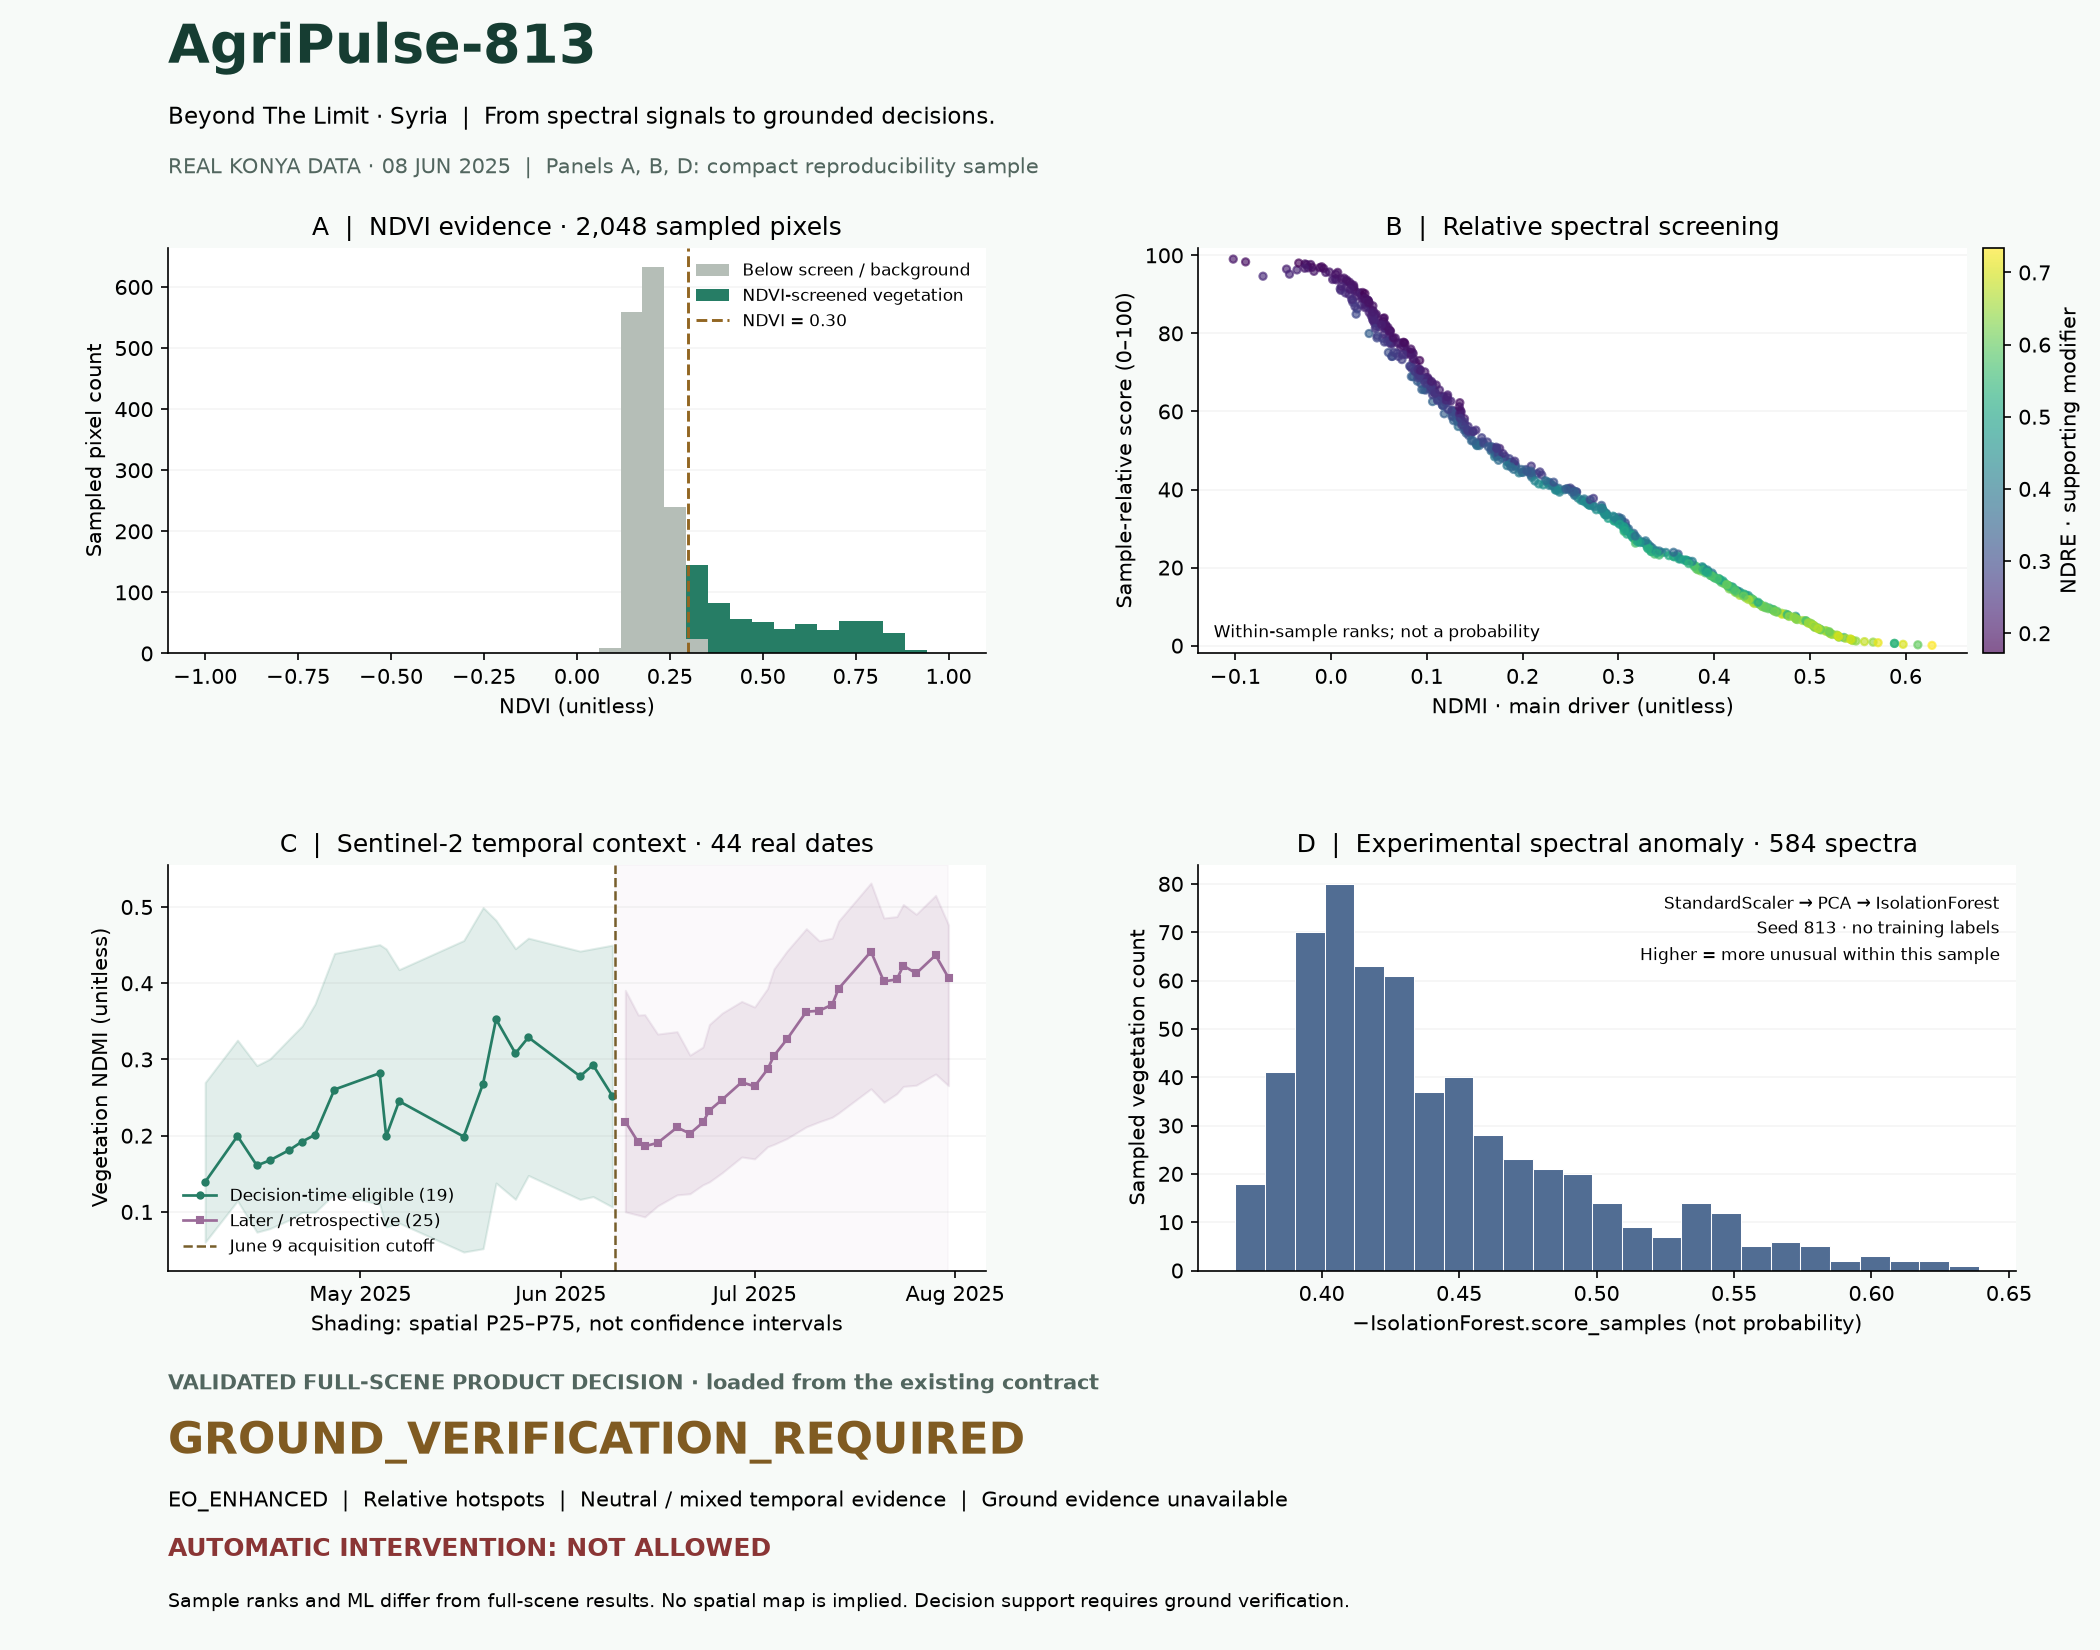

Saved: results/example_output.png


In [9]:
results = root / "results"
results.mkdir(exist_ok=True)
figure = workflow.make_figure(indices, screening, model, rows, contract, provenance)
figure.savefig(results / "example_output.png", dpi=150, facecolor=figure.get_facecolor(),
               metadata={"Software": "AgriPulse-813 submission workflow"})
plt.close(figure)
display(Image(filename=str(results / "example_output.png")))
print("Saved: results/example_output.png")

## 13. Generate the structured example summary
Separate `compact_sample_calculations` and `validated_full_scene_result` objects prevent sample
statistics from being confused with the authoritative decision. The JSON includes provenance,
source hashes, exact sample sizes, interpretation, cautions and limitations.
No fabricated confidence percentage is included. Runtime belongs to the execution report,
not the deterministic scientific summary. JSON contract hashes use semantic canonicalization;
CSV checks tolerate LF/CRLF checkout differences.

In [10]:
summary = workflow.make_summary(root, provenance, screening, model, rows, trends, contract, fusion)
(results / "example_summary.json").write_text(
    json.dumps(summary, indent=2, sort_keys=True, ensure_ascii=False, allow_nan=False) + "\n",
    encoding="utf-8", newline="\n")
print("Saved: results/example_summary.json")
print(json.dumps(summary["validated_full_scene_result"], indent=2))
print(f"Notebook computation wall time: {perf_counter() - started:.2f} seconds | Python {platform.python_version()} | GPU: NO")

Saved: results/example_summary.json
{
  "scope": "Loaded from the committed full-scene contract/evidence; not inferred from this sample.",
  "analysis_level": "EO_ENHANCED",
  "spectral_state": "RELATIVE_HOTSPOTS_PRESENT",
  "temporal_state": "NEUTRAL_OR_MIXED",
  "ground_state": "UNAVAILABLE",
  "final_decision": "GROUND_VERIFICATION_REQUIRED",
  "automation_allowed": false,
  "decision_as_of": "2025-06-09T08:35:59.024000Z",
  "ml_available": "AVAILABLE",
  "ml_used_for_decision": false,
  "recommended_next_action": "Review the hotspot map against field boundaries; obtain quality-checked, site-calibrated soil-moisture observations in representative hotspot and comparison areas before considering an intervention.",
  "sources": {
    "examples/product_contract_konya.json": {
      "canonical_json_sha256": "163aa27b3a74fbb509870e6442ed9cc65162c30c55efbfd4f94b5a3ff8eee6e7"
    },
    "dashboard/public/data/konya/fusion.json": {
      "canonical_json_sha256": "420feeb87ec29dfbc500ba7c5337

## 14. Interpret the result
The complete validated pipeline finds **RELATIVE_HOTSPOTS_PRESENT**, while the temporal evidence
is **NEUTRAL_OR_MIXED** and ground evidence is **UNAVAILABLE**. Near-Tanager NDMI does not
support a strong broad moisture decline. This does not exclude local concerns or identify their cause.

The decision remains **GROUND_VERIFICATION_REQUIRED**, at **EO_ENHANCED** capability, with
**automation_allowed: false**. Review hotspots against field boundaries and obtain quality-checked,
site-calibrated soil-moisture observations in representative hotspot and comparison areas before
considering intervention. Experimental ML describes spectral unusualness only and leaves this decision unchanged.

## 15. Limitations
- Compact-sample ranks, class counts, PCA and anomaly scores can differ from the full-scene results.
- Selection is uniform among quality-valid pixels, not balanced by field or crop; no spatial map is implied.
- The NDVI screen can omit sparse, senescent or affected vegetation and retain non-crop vegetation.
- Crop type, phenology, canopy density, soil, mixed pixels, residual atmosphere and shadows can confound shared spectral proxies.
- Sentinel vegetation populations and usable coverage vary by date; regional medians do not validate individual Tanager hotspots.
- The short seasonal reference is not a climatology, and later observations do not enter the June decision.
- Anomaly fitting and scoring are within-sample and unsupervised; no classification accuracy or causal diagnosis is claimed.
- Historical operational availability is not established. This is an acquisition-time-gated retrospective demonstration.
- The full raw scene is needed only to regenerate the exported inputs, never to run this notebook.
- Fixed seeds support repeatability; exact floating-point values can vary across hardware, numerical libraries and versions.

**Ground verification is required. Automatic intervention is not allowed.**